# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/StepTestFriday.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')
data['problem_type'] = numpy.select([data.problem_spc_tags.str.contains('FOF'), data.problem_spc_tags.str.contains('CNF')], ['FOF', 'CNF'], default = None)

good_problems = data.groupby('problem').strategy.nunique().loc[lambda x: x == x.max()].index
data = data[data.problem.isin(good_problems)]

# data = data[data.strategy.isin(valid_strategies.keys())].replace({'strategy': valid_strategies})
# data = data.sort_values(by = 'strategy', key = lambda x: x.replace({k: v for (v, k) in enumerate(valid_strategies.values())}))
# data = data.sort_values(by = 'strategy')

assert data.groupby('problem').strategy.count().nunique() == 1
assert data.groupby('strategy').problem.count().nunique() == 1
assert not data.problem_type.isnull().any()

In [5]:
data.strategy.value_counts()

strategy
SATCoP_0       16594
SATCoP         16594
SATResetCoP    16594
Name: count, dtype: int64

In [6]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
0,AGT001+1.p,SATCoP_0,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
1,AGT001+1.p,SATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
2,AGT001+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
3,AGT003+2.p,SATCoP_0,solved,Theorem (SAT),True,6086.0,47719.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
4,AGT003+2.p,SATCoP,solved,Theorem (SAT),True,6069.0,17978.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:6069,forward:549235,unique:139...",NaN,FOF


In [7]:
data.groupby('strategy').problem.nunique().sort_values()

strategy
SATCoP         16594
SATCoP_0       16594
SATResetCoP    16594
Name: problem, dtype: int64

In [8]:
data.groupby('strategy').steps.max()

strategy
SATCoP         1000000.0
SATCoP_0       1000000.0
SATResetCoP    1000000.0
Name: steps, dtype: float64

In [9]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,162,ALG,1389,ANA,288.0
1,BIO,18,BOO,450,CAT,402.0
2,COL,756,COM,225,CSR,2862.0
3,FLD,843,GEG,3,GEO,2688.0
4,GRA,102,GRP,3198,HAL,30.0
5,HEN,204,HWC,18,HWV,885.0
6,ITP,300,KLE,762,KRS,894.0
7,LAT,2274,LCL,2766,LDA,150.0
8,MED,36,MGT,474,MSC,75.0
9,MVA,45,NLP,1686,NUM,3189.0


# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data.groupby('strategy').problem.count()

strategy
SATCoP         16594
SATCoP_0       16594
SATResetCoP    16594
Name: problem, dtype: int64

In [12]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Non-Theorem: no positive start clauses,Theorem (SAT),All
strategy,,,
SATCoP_0,2,1880,1882
SATCoP,2,2522,2524
SATResetCoP,2,2980,2982
All,6,7382,7388


In [13]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
28077,PUZ053-1.p,SATCoP_0,timeout,NaN,False,6112.0,120006.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
28078,PUZ053-1.p,SATCoP,timeout,NaN,False,8068.0,120005.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:8068,forward:78444,unique:553,...",NaN,CNF
28079,PUZ053-1.p,SATResetCoP,timeout,NaN,False,7291.0,120029.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:7291,forward:133983,unique:853...",NaN,CNF


In [14]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,1497,2235,96,4356,16487,2652,15071
Non-Theorem: no positive start clauses,0,3,0,3,0,0,0
Theorem (SAT),90,0,0,0,3994,0,3298


In [15]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
0,AGT001+1.p,SATCoP_0,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
1,AGT001+1.p,SATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
2,AGT001+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
3,AGT003+2.p,SATCoP_0,solved,Theorem (SAT),True,6086.0,47719.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
4,AGT003+2.p,SATCoP,solved,Theorem (SAT),True,6069.0,17978.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:6069,forward:549235,unique:139...",NaN,FOF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49705,TOP005-2.p,SATCoP,solved,Theorem (SAT),True,22065.0,39193.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,unsat,"literal=choices:22065,forward:63335,unique:668...",NaN,CNF
49706,TOP005-2.p,SATResetCoP,solved,Theorem (SAT),True,3086.0,7160.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,unsat,"literal=choices:3086,forward:14913,unique:439,...",NaN,CNF
49722,TOP026+1.p,SATCoP_0,solved,Theorem (SAT),True,4017.0,18987.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
49723,TOP026+1.p,SATCoP,solved,Theorem (SAT),True,4441.0,10226.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:4441,forward:95878,unique:515,...",NaN,FOF


In [16]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    26337
Name: count, dtype: int64

In [17]:
data[data.solved].groupby('strategy').size()

strategy
SATCoP         2522
SATCoP_0       1880
SATResetCoP    2980
dtype: int64

# Results

<Axes: xlabel='strategy'>

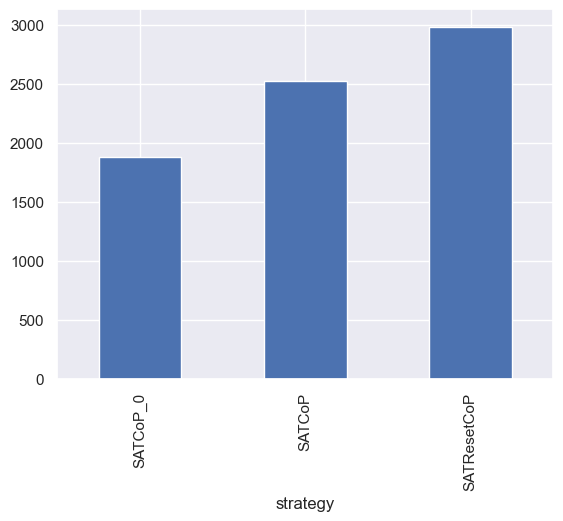

In [18]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [19]:
data.groupby(['strategy', 'problem_type']).solved.sum().unstack()

problem_type,CNF,FOF
strategy,,
SATCoP,1071,1451
SATCoP_0,804,1076
SATResetCoP,1278,1702


In [20]:
data[data.strategy == 'SATResetAtStaleAction'].result.value_counts()

Series([], Name: count, dtype: int64)

In [21]:
data[data.strategy == 'SATResetAtTwo'].result.value_counts()

Series([], Name: count, dtype: int64)

In [22]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [23]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,SATCoP,SATCoP_0,SATResetCoP
strategy_left,,,
SATCoP,16594,16594,16594
SATCoP_0,16594,16594,16594
SATResetCoP,16594,16594,16594


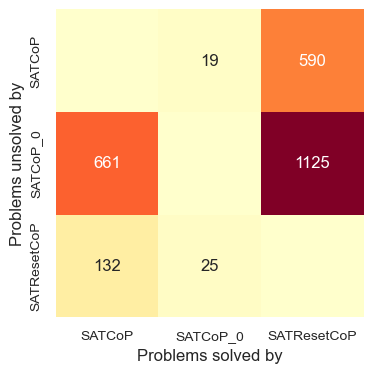

In [24]:
pyplot.rcParams['figure.figsize'] = (4, 4)
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

# order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Not solved by this model', columns = 'Solved by this model')
    # .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATCoP (orig)',
    'SATSolveLiteral': 'SATCoP',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
    'SATResetAtTwoFixedStep': 'ResetAtTwo\'',
    'SATResetAtTwo': 'ResetAtTwo',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Problems unsolved by', columns = 'Problems solved by').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    square = True,
    cbar = False,
)

pyplot.gca().tick_params(axis = 'both', labelsize = 'small')
pyplot.savefig('Vampire/figures/solved_heatmap.png', bbox_inches = 'tight', dpi = 400)

In [25]:
data[data.solved].time_ms.max()

119920.0

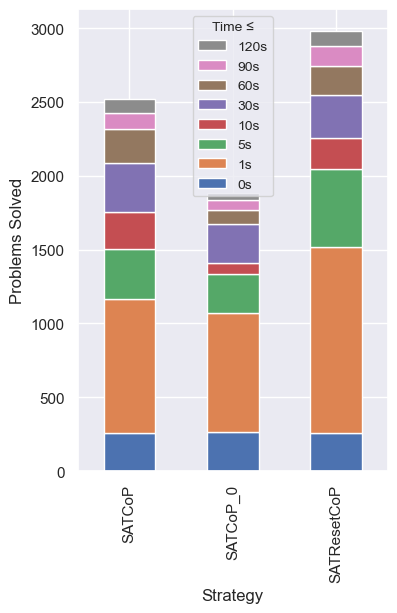

In [26]:
pyplot.rcParams["figure.figsize"] = (4, 6)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack()
b.columns = [f'{x}s' for x in b.columns]
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Time ≤', title_fontsize = 'small')

pyplot.savefig('Vampire/figures/strategy_solved_time_plot.png', dpi = 400, bbox_inches = 'tight')

In [27]:
b

,0s,1s,5s,10s,30s,60s,90s,120s
strategy,,,,,,,,
SATCoP,257,908,337,250,337,225,112,96
SATCoP_0,266,806,263,77,261,98,65,44
SATResetCoP,260,1256,530,207,297,192,137,101


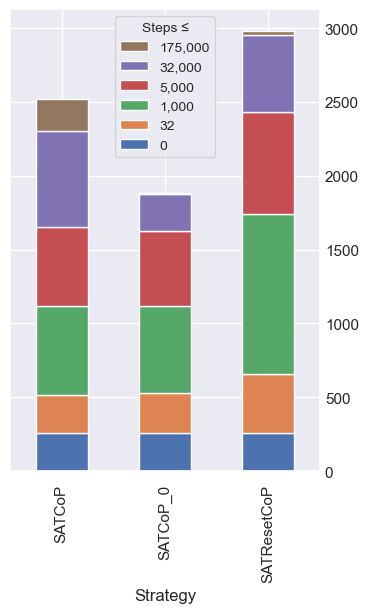

In [28]:
times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack()
b.columns = [f'{x:,d}' for x in b.columns]
b.plot.bar(stacked = True)
# pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')
pyplot.gca().yaxis.tick_right()
pyplot.gca().tick_params(axis = 'y', length = 0)

pyplot.savefig('Vampire/figures/strategy_solved_steps_plot.png', dpi = 400, bbox_inches = 'tight')

In [29]:
b

,0,32,"1,000","5,000","32,000","175,000"
strategy,,,,,,
SATCoP,255,262,602,535,651,217
SATCoP_0,255,276,587,508,250,4
SATResetCoP,255,401,1087,692,515,30


In [30]:
merged.strategy_right.unique()

array(['SATCoP_0', 'SATCoP', 'SATResetCoP'], dtype=object)

In [31]:
merged[(merged.strategy_left == 'SATSolveLiteral') & (merged.strategy_right == 'SATResetAtStaleAction') & merged.solved_right & merged.solved_left][['problem', 'steps_left', 'steps_right']]

,problem,steps_left,steps_right


In [32]:
merged.columns

Index(['problem', 'strategy_left', 'status_left', 'result_left', 'solved_left',
       'steps_left', 'time_ms_left', 'problem_spc_tags_left',
       'problem_typed_left', 'problem_declared_status_left',
       'problem_declared_status_kind_left', 'info_left', 'error_left',
       'problem_type_left', 'strategy_right', 'status_right', 'result_right',
       'solved_right', 'steps_right', 'time_ms_right',
       'problem_spc_tags_right', 'problem_typed_right',
       'problem_declared_status_right', 'problem_declared_status_kind_right',
       'info_right', 'error_right', 'problem_type_right'],
      dtype='object')

In [33]:
merged[
    (merged.strategy_left == 'FirstAction') &
    (merged.strategy_right == 'SATSolve') &
    merged.solved_right &
    merged.solved_left &
    (merged.steps_right == 0) &
    (merged.steps_left < 10000)
    ][['problem', 'time_ms_left', 'steps_left', 'time_ms_right', 'steps_right']].sort_values('steps_left', ascending = False)

,problem,time_ms_left,steps_left,time_ms_right,steps_right


In [34]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
0,AGT001+1.p,SATCoP_0,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
1,AGT001+1.p,SATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
2,AGT001+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
3,AGT003+2.p,SATCoP_0,solved,Theorem (SAT),True,6086.0,47719.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
4,AGT003+2.p,SATCoP,solved,Theorem (SAT),True,6069.0,17978.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:6069,forward:549235,unique:139...",NaN,FOF


In [35]:
pandas.concat(
    [
        data[data.solved & (data.problem_type == 'CNF')].groupby('problem').first().strategy.value_counts().rename('CNF'),
        data[data.solved & (data.problem_type == 'FOF')].groupby('problem').first().strategy.value_counts().rename('FOF'),
    ],
    axis = 1,
)

,CNF,FOF
strategy,,
SATCoP_0,804,1076
SATCoP,277,384
SATResetCoP,254,320


## Violinplots

<Axes: xlabel='time_ms', ylabel='problem'>

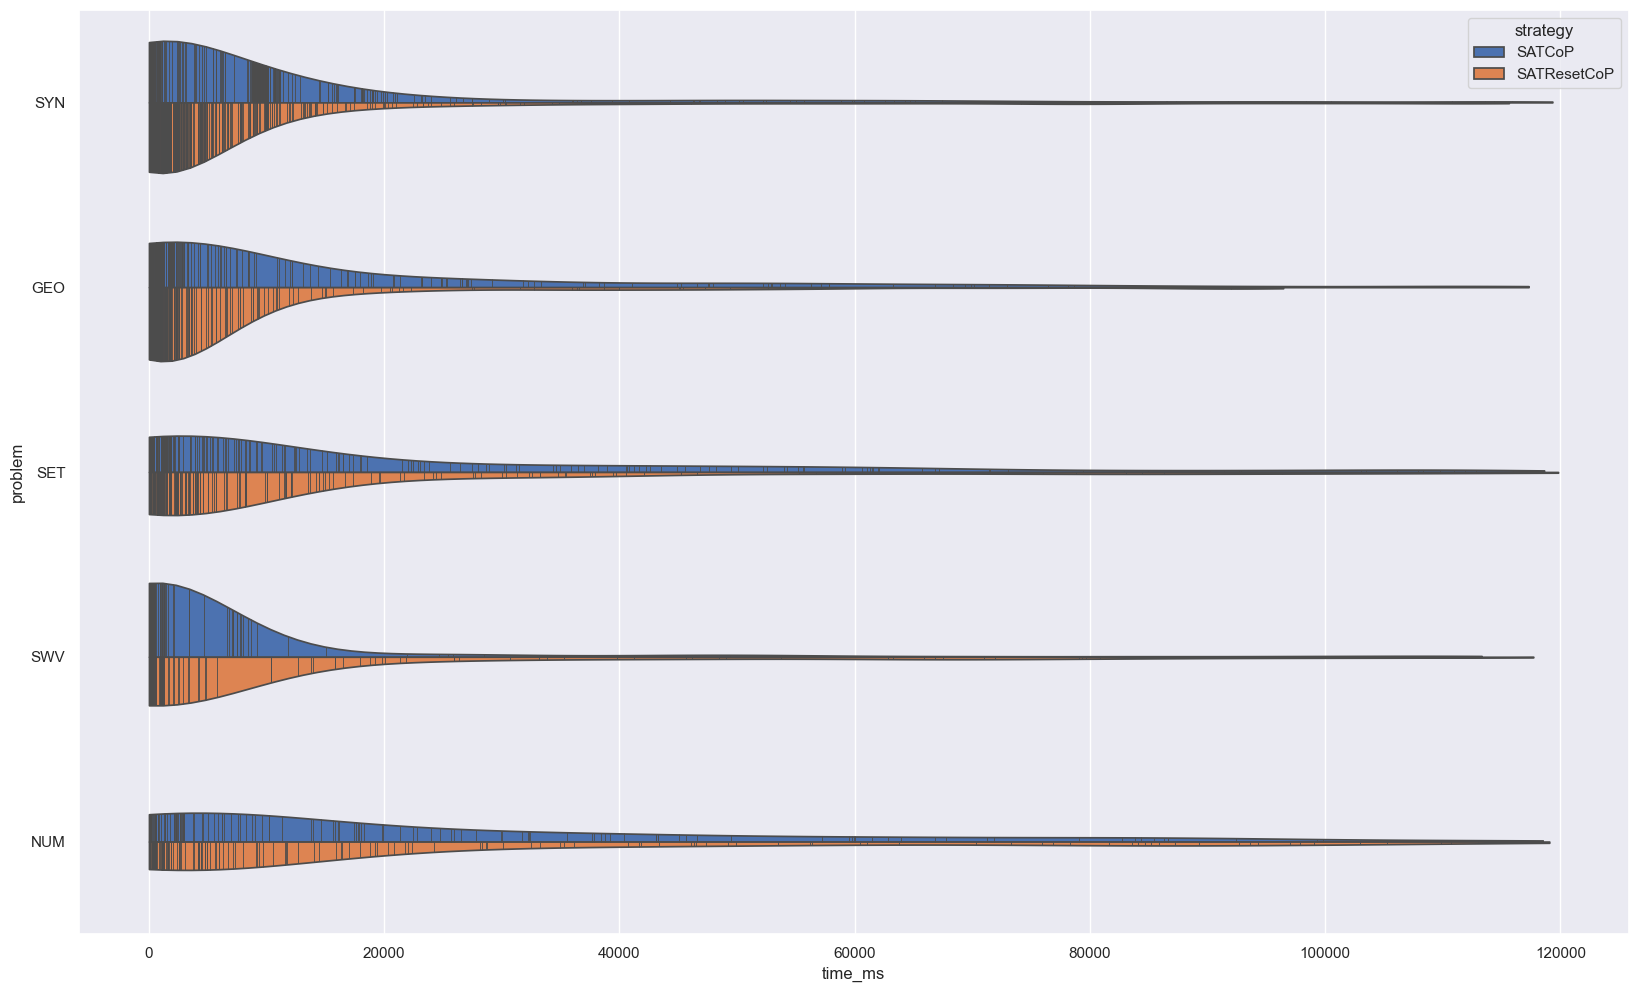

In [36]:
pyplot.rcParams["figure.figsize"] = (20, 12)
categories = data[data.solved & (data.strategy == 'SATResetCoP')].problem.str[:3].value_counts()[:5].index
down = data[data.solved & data.strategy.isin(['SATCoP', 'SATResetCoP']) & data.problem.str[:3].isin(categories)].copy()
seaborn.violinplot(
    down,
    x = 'time_ms',
    y = down.problem.str[:3],
    order = categories,
    hue = down.strategy,
    fill = True,
    inner = 'stick',
    split = True,
    cut = 0,
    saturation = 1,
)

In [37]:
down.problem.value_counts().value_counts()

count
2    1343
1     362
Name: count, dtype: int64

In [38]:
down.loc[lambda x: x.time_ms < 90000].sort_values('time_ms', ascending = False)

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
41066,SWV206+1.p,SATResetCoP,solved,Theorem (SAT),True,785.0,89954.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:785,forward:191340,unique:51,t...",NaN,FOF
26819,NUM441+6.p,SATResetCoP,solved,Theorem (SAT),True,13944.0,89268.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"score=1.0; literal=choices:13944,forward:75797...",NaN,FOF
45509,SYN784-1.p,SATResetCoP,solved,Theorem (SAT),True,37715.0,88639.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,unsat,score=3.160664819944598; literal=choices:37715...,NaN,CNF
8539,GEO048-3.p,SATCoP,solved,Theorem (SAT),True,22447.0,87430.0,CNF_UNS_RFO_SEQ_NHN,False,Unsatisfiable,unsat,"literal=choices:22447,forward:349020,unique:36...",NaN,CNF
8077,GEO112+1.p,SATCoP,solved,Theorem (SAT),True,58612.0,87288.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"score=1.0; literal=choices:58612,forward:57319...",NaN,FOF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47333,SYN379+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_EPR_NEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
42245,SWV078+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
40339,SWV045+1.p,SATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
45152,SYN343+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF


In [39]:
data.strategy.value_counts()

strategy
SATCoP_0       16594
SATCoP         16594
SATResetCoP    16594
Name: count, dtype: int64

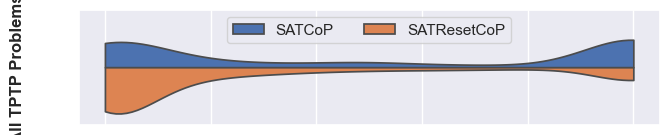

In [40]:
from matplotlib.ticker import FuncFormatter

pyplot.rcParams["figure.figsize"] = (7.5, 1.5)
lim = 10000

down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved | (down.steps > lim), 'steps'] = lim
down.loc[:, 'dummy'] = 'SWV'

seaborn.violinplot(
    down,
    y = 'dummy',
    x = 'steps',
    hue = down.strategy,
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = 1,
    density_norm = 'area',
    common_norm = True,
    legend = True,
)

pyplot.ylabel('All TPTP Problems')
pyplot.xlabel('Steps to Solve')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: (f'≥' if x == lim else '') +  f'{int(x // 1000)}k'))
pyplot.gca().set_xticklabels([])
pyplot.gca().set_xlabel('')
pyplot.gca().get_yticklabels()[0].set_color('white')
pyplot.gca().yaxis.label.set_fontweight('bold')

pyplot.legend(title = '', ncols = 2, loc = 9)

pyplot.savefig('Paris_slides/figures/violinplot_all_problems.png', dpi = 300)

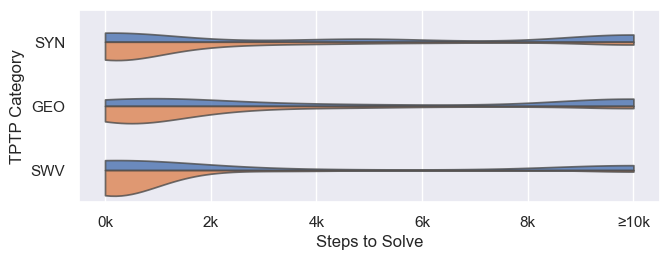

In [41]:
from matplotlib.ticker import FuncFormatter

lim = 10000
cats = ['SYN', 'GEO', 'SWV']

pyplot.rcParams["figure.figsize"] = (7.5, 2.5)
down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[:, 'category'] = down.problem.str[:3]
down.loc[~down.solved | (down.steps > lim), 'steps'] = lim

seaborn.violinplot(
    down,
    y = 'category',
    x = 'steps',
    order = cats,
    hue = down.strategy,
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = 1,
    density_norm = 'area',
    common_norm = True,
    alpha = .8,
    legend = False,
)

# ax.get_yticklabels()[0].set_fontweight('bold')
# ax.get_yticklabels()[0].set_fontsize(12)
# ax.set_facecolor('#EEEEF5')

pyplot.ylabel('TPTP Category')
pyplot.xlabel('Steps to Solve')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: (f'≥' if x == lim else '') +  f'{int(x // 1000)}k'))
# pyplot.legend(title = '', ncols = 2, loc = 0)

# pyplot.suptitle(f'Steps needed to solve {len(down)} problems', fontsize = 20)
# pyplot.title(f'(Violins normalised to the same area)')

pyplot.savefig('Paris_slides/figures/violinplot.png', dpi = 300)

In [42]:
a = ax.get_yticklabels()[0]

NameError: name 'ax' is not defined

In [ ]:
a.set_f

In [ ]:
from matplotlib.ticker import FuncFormatter

pyplot.rcParams["figure.figsize"] = (10, 5.5)
down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved, 'steps'] = 100000
# down.loc[down.strategy == 'SATCoP_2', 'strategy'] = 'SATCoP'
# down = down[down.problem.str[:3].isin(['SYN', 'SYO', 'SET', """ 'SWV', 'ALG' """])]
seaborn.violinplot(
    down,
    x = 'steps',
    hue = down.strategy,
    # y = down.problem.str[:3],
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = .75,
    density_norm = 'area',
    common_norm = True,
)

pyplot.ylabel('TPTP Category')
pyplot.xlabel('Steps to Solve')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: 'Unsolved' if x == 100000 else f'{int(x // 1000)}k'))
pyplot.legend(title = '', ncols = 2, loc = 0)

# pyplot.savefig('Paris_slides/figures/violinplot.png', bbox_inches = 'tight', dpi = 300)

In [ ]:
for k, v in down[down.problem.str[:3] == 'SWV'].groupby('strategy'):
    v.steps.hist()
    pyplot.ylim(0, 250)
    pyplot.show()

In [ ]:
data.strategy.value_counts()

In [ ]:
a = down
pandas.crosstab(
    a.strategy,
    a.solved,
)

In [ ]:
%pwd

In [ ]:
pyplot.rcParams["figure.figsize"] = (20, 12)
down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved, 'steps'] = 100000
seaborn.violinplot(
    down,
    x = 'steps',
    hue = down.strategy,
    fill = True,
    # inner = 'stick',
    split = True,
    cut = 0,
    # saturation = 1,
)

## Single Tree

In [ ]:
(
    data
    .sort_values('problem')
    [data.strategy.isin(['SATCoP', 'SATResetCoP'])]
    .iloc[:10]
    .groupby('problem')
    .filter(lambda x: x.solved.all())
    .groupby('problem')
    .apply(lambda x: 0)
)

In [ ]:
data.strategy.unique()

In [ ]:
comp = merged[
    (merged.strategy_left == 'SATCoP_2') & (merged.strategy_right == 'SATResetCoP') & merged.solved_left & merged.solved_right
]
comp.loc[:, 'step_diff'] = comp.steps_right - comp.steps_left
best = (
    comp
    [(comp.steps_left < 300) & (comp.steps_right < 300)]
    .sort_values('step_diff')[['problem', 'steps_left', 'steps_right', 'step_diff']]
    .loc[lambda x: x.problem.str.contains('-') & x.problem.str.contains('SYN')]
    .head(20)
)
best

In [ ]:
' '.join(best.problem)

# Verification

In [ ]:
verify = pandas.read_csv('results/SATReset10MinutesFull.csv')

In [ ]:
verify

In [ ]:
a = verify[verify.problem_spc_tags.str.contains('FOF')]
b = verify[verify.problem_spc_tags.str.contains('CNF')]

pandas.concat(
    [
        pandas.crosstab(a.problem_declared_status, a.solved),
        pandas.crosstab(b.problem_declared_status, b.solved),
    ],
    keys = ['FOF', 'CNF'],
    axis = 1,
).fillna(0).astype(int)

In [ ]:
pandas.crosstab(
    a.problem_declared_status,
    a.solved,
)